# 12 — Reward Modeling

## Terms & Definitions
- **Reward model (RM)**: a model that takes a (prompt, response) pair and outputs a single scalar score estimating how "good" that response is — used to guide RL fine-tuning (notebook 13).
- **Preference pair**: a training example consisting of a prompt plus two candidate responses, one marked *chosen* (preferred) and one *rejected* (dispreferred) — no absolute quality score needed, just a relative preference.
- **Bradley-Terry model**: a classical statistical model (1952) for predicting the probability that one item beats another in a pairwise comparison, based on each item's underlying "strength" score. RLHF reward models are trained exactly this way, with the reward model's output playing the role of "strength."
- **Reward head**: a small additional output layer (here, a single linear layer producing one number) attached to a language model backbone, replacing the usual `lm_head` that predicts a whole vocabulary distribution.

## Why We Need a Reward Model At All
SFT (notebook 11) teaches a model to produce *plausible* instruction-following responses, but it can't teach fine-grained quality distinctions — SFT only sees positive examples (no notion of "this response is better than that one"), and collecting absolute quality scores from humans for every possible response is impractical/expensive.

**Preference pairs are much easier to collect than absolute scores**: it's far easier for a human (or, in our toy case, a simple rule) to say "response A is better than response B" than to say "response A is a 7.3 out of 10." RLHF's first step is training a reward model to predict these pairwise preferences, so that later (notebook 13) we can use its scalar output as an automatic reward signal for RL — without needing a human in the loop for every single training example.

## History
This general approach — RL fine-tuning guided by a learned reward model trained on human preferences — was formalized in **"Deep Reinforcement Learning from Human Preferences"** (Christiano et al., 2017) and became central to LLM alignment via **InstructGPT** (2022) and its descendants (ChatGPT, Claude's early RLHF stages, etc.). The reward model itself is usually just the SFT model with its language-modeling head replaced by a scalar reward head, then trained on human-labeled preference pairs.

## The Math (light): Bradley-Terry Loss

Given a prompt, a chosen response $y_w$, and a rejected response $y_l$, with the reward model producing scores $r(y_w)$ and $r(y_l)$, the Bradley-Terry model says the probability the chosen response is indeed preferred is:

$$P(y_w \succ y_l) = \sigma(r(y_w) - r(y_l))$$

where $\sigma$ is the sigmoid function. We train the reward model to maximize this probability for our labeled preference pairs, which is equivalent to minimizing:

$$\mathcal{L} = -\log\sigma(r(y_w) - r(y_l))$$

Intuitively: push the chosen response's score *up* and the rejected response's score *down*, relative to each other — the loss only cares about the *difference* between the two scores, not their absolute values.

## Our Toy Preference Data
`data/preference_pairs.jsonl` (generated in `scripts/generate_instruction_data.py`) pairs each prompt with an obviously correct/well-formed response (chosen) and an obviously wrong/malformed one (rejected) — e.g. correct vs. incorrect arithmetic, or correctly- vs incorrectly-cased text. This gives our toy reward model an unambiguous signal to learn from.


In [1]:
import sys
sys.path.insert(0, "..")

import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from src.model import GPTMicro, GPTConfig
from src.data import train_bpe_tokenizer, load_electricity_for_boys, PreferenceDataset, set_seed
from src.train_utils import save_checkpoint, load_checkpoint, plot_losses

torch.set_num_threads(6)
set_seed(1337)


## Reward Model = SFT Backbone + Scalar Reward Head

We reuse the pretrained Transformer backbone from `sft_electricity` (so it already understands language and our toy instruction format), and add a small linear head that maps the hidden state of the *last real (non-padding) token* in a sequence to a single scalar reward.

Note the "last real token" qualifier: our sequences are padded out to a fixed `block_size` with `<pad>` tokens (see `src/data.py: PreferenceDataset`), so naively taking position `[-1]` would read the hidden state of a padding token instead of the actual end of the response. We track each sequence's true (unpadded) length and gather the hidden state at `length - 1` instead.


In [2]:
class RewardModel(nn.Module):
    def __init__(self, base_config: GPTConfig, base_checkpoint_name: str):
        super().__init__()
        self.backbone = GPTMicro(base_config)
        load_checkpoint(self.backbone, base_checkpoint_name, device="cpu")
        self.reward_head = nn.Linear(base_config.n_embd, 1)

    def forward(self, input_ids, lengths):
        # Run the backbone up through its final LayerNorm, but skip lm_head --
        # we want the raw hidden state, not a vocabulary distribution.
        B, T = input_ids.shape
        pos = torch.arange(T, device=input_ids.device)
        x = self.backbone.token_emb(input_ids) + self.backbone.pos_emb(pos)
        x = self.backbone.dropout(x)
        for block in self.backbone.blocks:
            x = block(x)
        x = self.backbone.ln_f(x)          # (B, T, n_embd)

        # Gather the hidden state at each sequence's last REAL token (not padding).
        last_idx = (lengths - 1).clamp(min=0)               # (B,)
        last_hidden = x[torch.arange(B), last_idx]            # (B, n_embd)
        reward = self.reward_head(last_hidden).squeeze(-1)   # (B,)
        return reward

config = GPTConfig(vocab_size=8000, block_size=128, n_layer=6, n_head=8, n_embd=480, dropout=0.1)
reward_model = RewardModel(config, "sft_electricity")
print(f"reward model backbone + head: {sum(p.numel() for p in reward_model.parameters())/1e6:.2f}M params")


reward model backbone + head: 20.53M params


## Load Preference Data


In [4]:
text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)

pref_dataset = PreferenceDataset("../data/preference_pairs.jsonl", tokenizer, block_size=config.block_size)
print(f"preference pairs: {len(pref_dataset)}")

chosen_ids, chosen_len, rejected_ids, rejected_len = pref_dataset[0]
print("chosen  :", tokenizer.decode(chosen_ids[:chosen_len].tolist()))
print("rejected:", tokenizer.decode(rejected_ids[:rejected_len].tolist()))





preference pairs: 1000
chosen  :  Instruction:
Convert 'current' to title case.
 Response:
Current
rejected:  Instruction:
Convert 'current' to title case.
 Response:
CURRENT


## Sanity Check: Reward Model Before Training

Before any training, the reward head is randomly initialized, so it shouldn't reliably rank chosen above rejected -- roughly 50/50.


In [6]:
@torch.no_grad()
def fraction_correctly_ranked(model, dataset, n_samples=100):
    correct = 0
    for i in range(min(n_samples, len(dataset))):
        chosen, chosen_len, rejected, rejected_len = dataset[i]
        r_chosen = model(chosen.unsqueeze(0), torch.tensor([chosen_len]))
        r_rejected = model(rejected.unsqueeze(0), torch.tensor([rejected_len]))
        if r_chosen.item() > r_rejected.item():
            correct += 1
    return correct / min(n_samples, len(dataset))

reward_model.eval()
acc_before = fraction_correctly_ranked(reward_model, pref_dataset)
print(f"fraction ranked correctly BEFORE training: {acc_before:.1%}  (expect ~50% -- random)")


fraction ranked correctly BEFORE training: 60.0%  (expect ~50% -- random)


## Train the Reward Model


In [7]:
def collate_pairs(batch):
    chosen = torch.stack([c for c, cl, r, rl in batch])
    chosen_lens = torch.tensor([cl for c, cl, r, rl in batch])
    rejected = torch.stack([r for c, cl, r, rl in batch])
    rejected_lens = torch.tensor([rl for c, cl, r, rl in batch])
    return chosen, chosen_lens, rejected, rejected_lens

batch_size = 16
n_epochs = 2
lr = 1e-4

loader = DataLoader(pref_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_pairs)
optimizer = torch.optim.AdamW(reward_model.parameters(), lr=lr, weight_decay=0.01)

reward_model.train()
losses = []
t0 = time.time()
for epoch in range(n_epochs):
    for chosen, chosen_lens, rejected, rejected_lens in loader:
        r_chosen = reward_model(chosen, chosen_lens)
        r_rejected = reward_model(rejected, rejected_lens)

        # Bradley-Terry loss: push r_chosen - r_rejected to be large and positive.
        loss = -F.logsigmoid(r_chosen - r_rejected).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    print(f"epoch {epoch+1}/{n_epochs}  loss {losses[-1]:.4f}  ({time.time()-t0:.0f}s elapsed)")

print(f"\nreward model training complete in {time.time()-t0:.0f}s")


epoch 1/2  loss 0.2648  (105s elapsed)
epoch 2/2  loss 0.1852  (220s elapsed)

reward model training complete in 220s


epoch 2/2  loss 0.1852  (212s elapsed)

reward model training complete in 212s


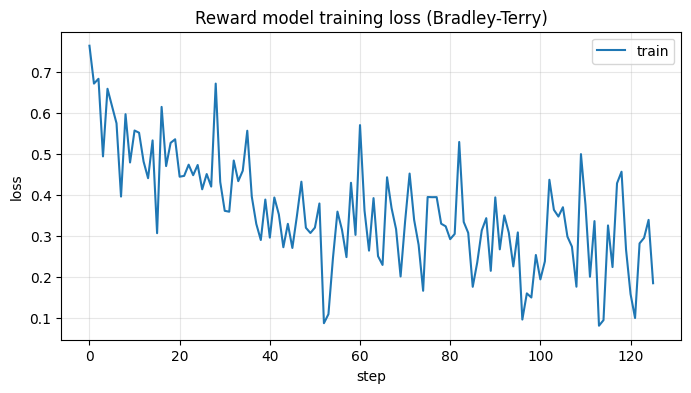

In [8]:
plot_losses(losses, title="Reward model training loss (Bradley-Terry)")


In [9]:
reward_model.eval()
acc_after = fraction_correctly_ranked(reward_model, pref_dataset)
print(f"fraction ranked correctly BEFORE training: {acc_before:.1%}")
print(f"fraction ranked correctly AFTER  training: {acc_after:.1%}")


fraction ranked correctly BEFORE training: 60.0%
fraction ranked correctly AFTER  training: 86.0%


The trained reward model should rank chosen-above-rejected far more often than the untrained ~50% baseline -- this confirms it learned a meaningful, generalizable preference signal from our toy pairs, not just memorized noise.


In [10]:
import torch as _torch  # local alias to avoid shadowing in checkpoint saving below

path = save_checkpoint(reward_model.backbone, "reward_model_backbone")
_torch.save(reward_model.reward_head.state_dict(), path.parent / "reward_head.pt")
print("saved reward model backbone + head")


saved reward model backbone + head


## Exercise
Try a manual example: encode `"What is 5 + 5?"` paired with the correct response `"10"` versus an incorrect response `"11"`, and check which one the trained reward model scores higher.


In [11]:
from src.data import InstructionDataset

def score_response(reward_model, tokenizer, prompt, response, block_size):
    text = InstructionDataset.PROMPT_TEMPLATE.format(instruction=prompt) + response
    ids = tokenizer.encode(text).ids[:block_size]
    length = len(ids)
    pad_id = tokenizer.token_to_id("<pad>")
    ids = ids + [pad_id] * (block_size - len(ids))
    with torch.no_grad():
        return reward_model(torch.tensor([ids]), torch.tensor([length])).item()

good_score = score_response(reward_model, tokenizer, "What is 5 + 5?", "10", config.block_size)
bad_score = score_response(reward_model, tokenizer, "What is 5 + 5?", "11", config.block_size)
print(f"reward('10'): {good_score:.3f}")
print(f"reward('11'): {bad_score:.3f}")
print("correctly prefers '10':", good_score > bad_score)


reward('10'): 2.058
reward('11'): 1.920
correctly prefers '10': True


## Summary
- A reward model turns (prompt, response) into a single scalar score, trained on preference pairs rather than absolute labels.
- Training uses the Bradley-Terry loss: maximize the probability the model assigns higher reward to the chosen response than the rejected one.
- We built ours by attaching a scalar reward head to our SFT backbone, and confirmed it learns to correctly rank chosen-over-rejected far above the ~50% untrained baseline.
- This trained reward model is exactly what notebook 13's PPO loop will use as its reward signal.

Next: **13 — Reinforcement Learning (PPO)** (use this reward model to actually fine-tune the policy via RL — the second half of RLHF).
